In [76]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import tensorflow as tf

In [54]:
"""
The goal is to follow a simple and correct machine learning pipeline:
Load and understand the data.
Clean the data.
Explore the data.
Prepare the data for modeling.
Split into training and testing sets.
Scale the data correctly without data leakage.
Build and train an ANN model.
Evaluate and improve the model.
"""

'\nThe goal is to follow a simple and correct machine learning pipeline:\nLoad and understand the data.\nClean the data.\nExplore the data.\nPrepare the data for modeling.\nSplit into training and testing sets.\nScale the data correctly without data leakage.\nBuild and train an ANN model.\nEvaluate and improve the model.\n'

In [55]:
# Step 1: Load the Dataset
data = load_breast_cancer(as_frame=True)
df = data.frame
df

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,1.1760,1.2560,7.673,158.70,0.010300,0.02891,0.05198,0.02454,0.01114,0.004239,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,0
565,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,0.7655,2.4630,5.203,99.04,0.005769,0.02423,0.03950,0.01678,0.01898,0.002498,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,0
566,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,0.4564,1.0750,3.425,48.55,0.005903,0.03731,0.04730,0.01557,0.01318,0.003892,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,0
567,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,0.7260,1.5950,5.772,86.22,0.006522,0.06158,0.07117,0.01664,0.02324,0.006185,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,0


In [56]:
print(df.head())

   mean radius  mean texture  ...  worst fractal dimension  target
0        17.99         10.38  ...                  0.11890       0
1        20.57         17.77  ...                  0.08902       0
2        19.69         21.25  ...                  0.08758       0
3        11.42         20.38  ...                  0.17300       0
4        20.29         14.34  ...                  0.07678       0

[5 rows x 31 columns]


In [57]:
print(df.size)
print(df.shape)
print(df.columns)
# 30 features, 1 target

17639
(569, 31)
Index(['mean radius', 'mean texture', 'mean perimeter', 'mean area',
       'mean smoothness', 'mean compactness', 'mean concavity',
       'mean concave points', 'mean symmetry', 'mean fractal dimension',
       'radius error', 'texture error', 'perimeter error', 'area error',
       'smoothness error', 'compactness error', 'concavity error',
       'concave points error', 'symmetry error', 'fractal dimension error',
       'worst radius', 'worst texture', 'worst perimeter', 'worst area',
       'worst smoothness', 'worst compactness', 'worst concavity',
       'worst concave points', 'worst symmetry', 'worst fractal dimension',
       'target'],
      dtype='str')


<Axes: xlabel='target', ylabel='count'>

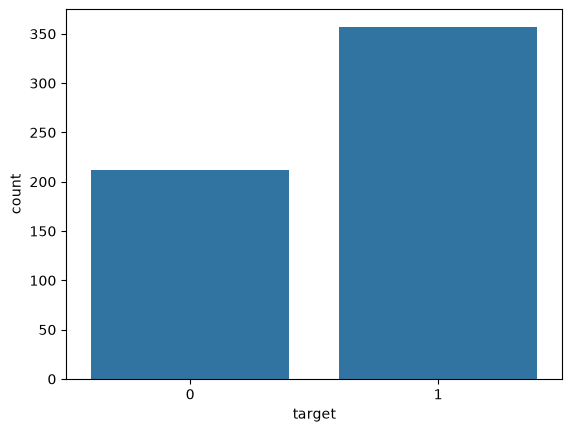

In [58]:
sns.countplot(data=df, x="target")
# Problem: Imbalance in class distribution of target, so may bias to class 1
# Also another problem is that there are TOO MANY features (overfitting may occur)

In [59]:
# Step 2: Clean the Data
print(df.isna().sum()) # NO missing values

mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
target                     0
dtype: int64


In [60]:
print(df.duplicated().sum()) # No dupe rows

0


In [61]:
print(df.info()) # NO categ data (all numbers)
# all features are numerical

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         569 non-null

In [62]:
# Target class is "target", Binary class: 0 or 1

# NO Issues in data: no dupes, no missing values, no categorical data (all numerical) 

<Axes: xlabel='target', ylabel='count'>

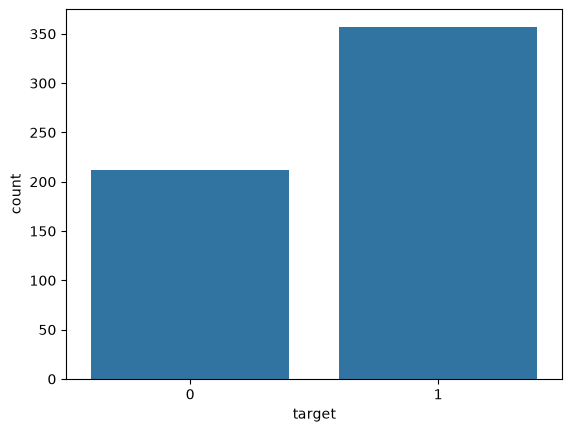

In [63]:
# Step 3: Perform Simple EDA

features = df.drop(columns="target")
target = df["target"]

sns.countplot(data=df, x="target") # Class distribution plot.

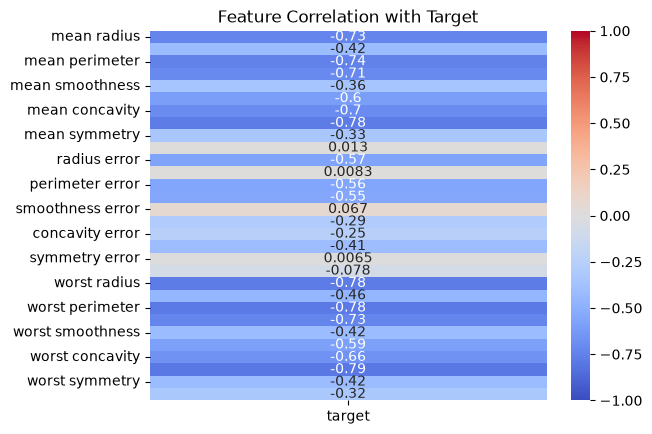

In [64]:
# Correlation heatmap.

corr = features.select_dtypes(include="number").corrwith(target).to_frame("target")# Calculate correlations (all features against target)


sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Feature Correlation with Target")
plt.show()

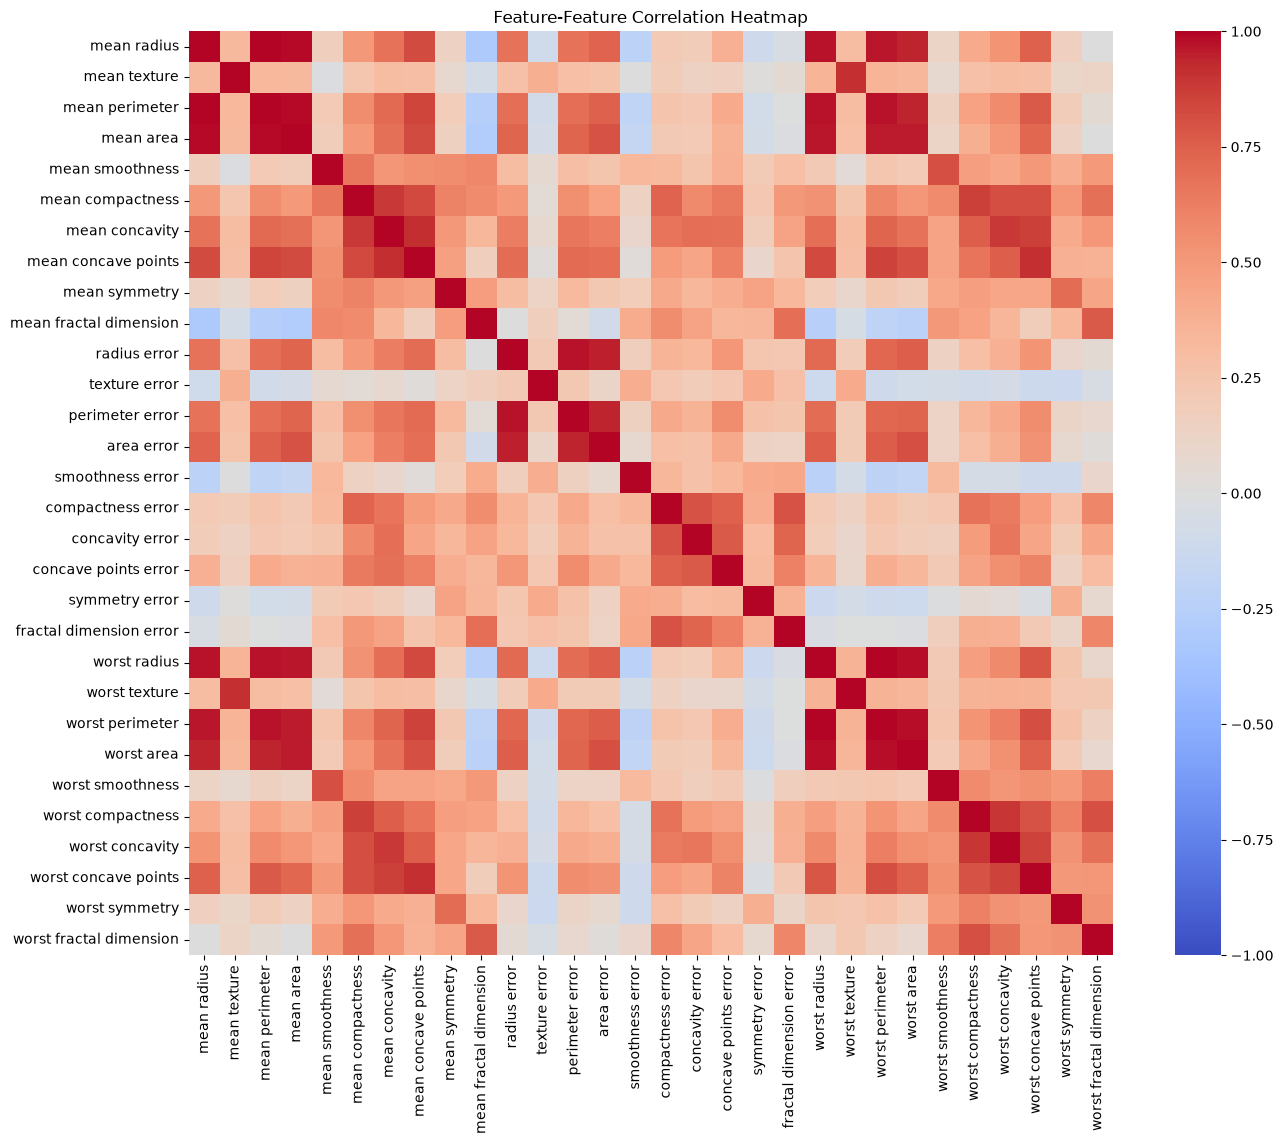

In [65]:
# Correlation heatmap (feature vs feature) to decide which ones to keep/drop. (We want to drop features that are highly correlated with each other, as they are redundant and may cause overfitting.)

plt.figure(figsize=(16, 12))
feat_corr = features.corr()
sns.heatmap(feat_corr, cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Feature-Feature Correlation Heatmap")
plt.show()

In [66]:
# Features most correlated with the target (sorted by absolute value)
target_corr = features.corrwith(target)
target_corr_sorted = target_corr.abs().sort_values(ascending=False)
print("Features most correlated with the target (sorted by absolute value):")
print(target_corr_sorted)

Features most correlated with the target (sorted by absolute value):
worst concave points       0.793566
worst perimeter            0.782914
mean concave points        0.776614
worst radius               0.776454
mean perimeter             0.742636
worst area                 0.733825
mean radius                0.730029
mean area                  0.708984
mean concavity             0.696360
worst concavity            0.659610
mean compactness           0.596534
worst compactness          0.590998
radius error               0.567134
perimeter error            0.556141
area error                 0.548236
worst texture              0.456903
worst smoothness           0.421465
worst symmetry             0.416294
mean texture               0.415185
concave points error       0.408042
mean smoothness            0.358560
mean symmetry              0.330499
worst fractal dimension    0.323872
compactness error          0.292999
concavity error            0.253730
fractal dimension error    0.07

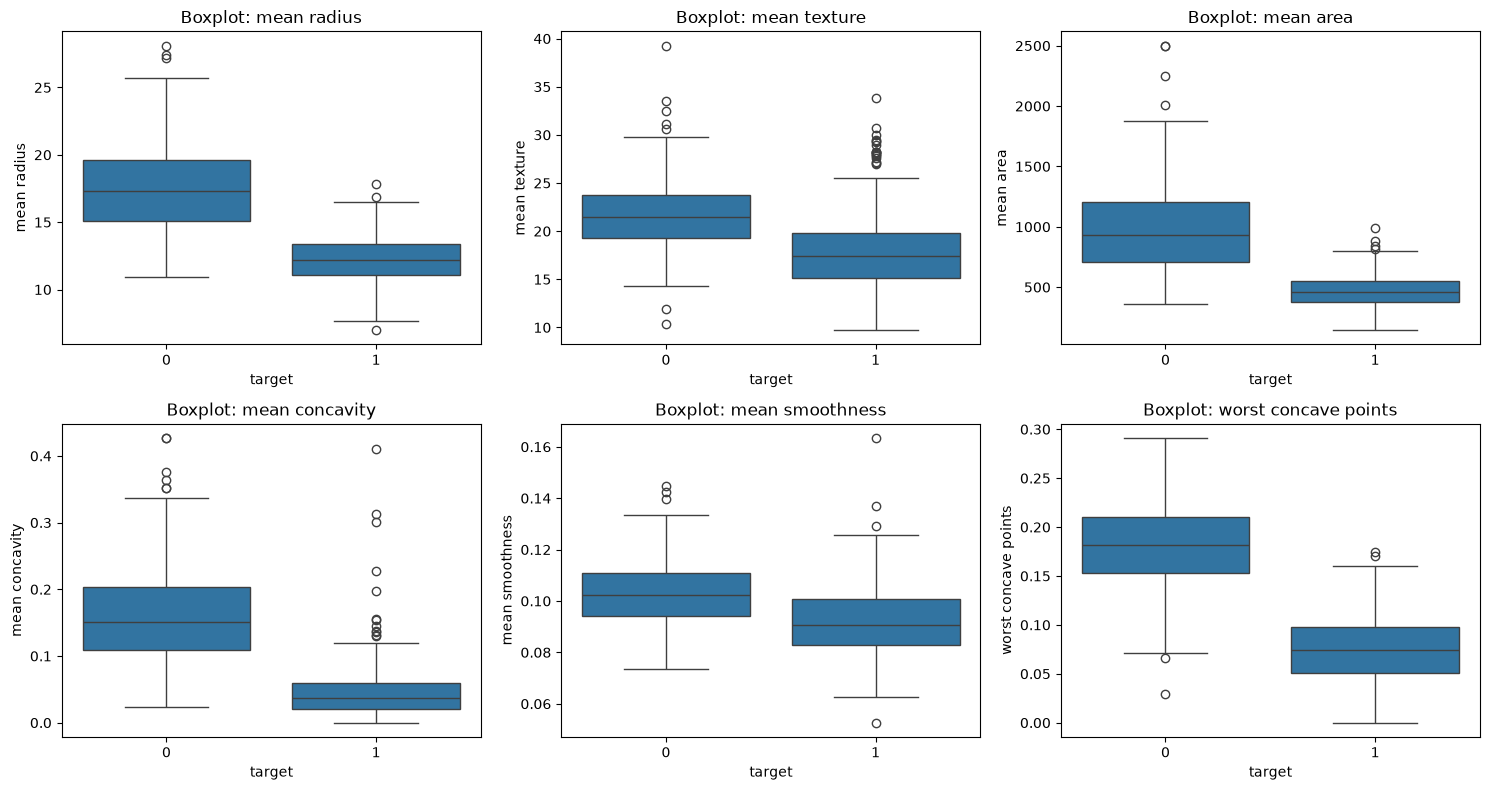

mean radius: 14 outliers
mean texture: 7 outliers
mean area: 25 outliers
mean concavity: 18 outliers
mean smoothness: 6 outliers
worst concave points: 0 outliers


In [67]:
# Boxplots for selected numerical features 
selected_features = ["mean radius", "mean texture", "mean area",
            "mean concavity", "mean smoothness", "worst concave points"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.ravel()
for i, col in enumerate(selected_features):
    sns.boxplot(data=df, x="target", y=col, ax=axes[i])
    axes[i].set_title(f"Boxplot: {col}")
plt.tight_layout()
plt.show()

# Count outliers using the IQR rule
for col in selected_features:
    q1= df[col].quantile(0.25)
    q3= df[col].quantile(0.75)
    iqr = q3 - q1
    n_outliers = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()
    print(f"{col}: {n_outliers} outliers")

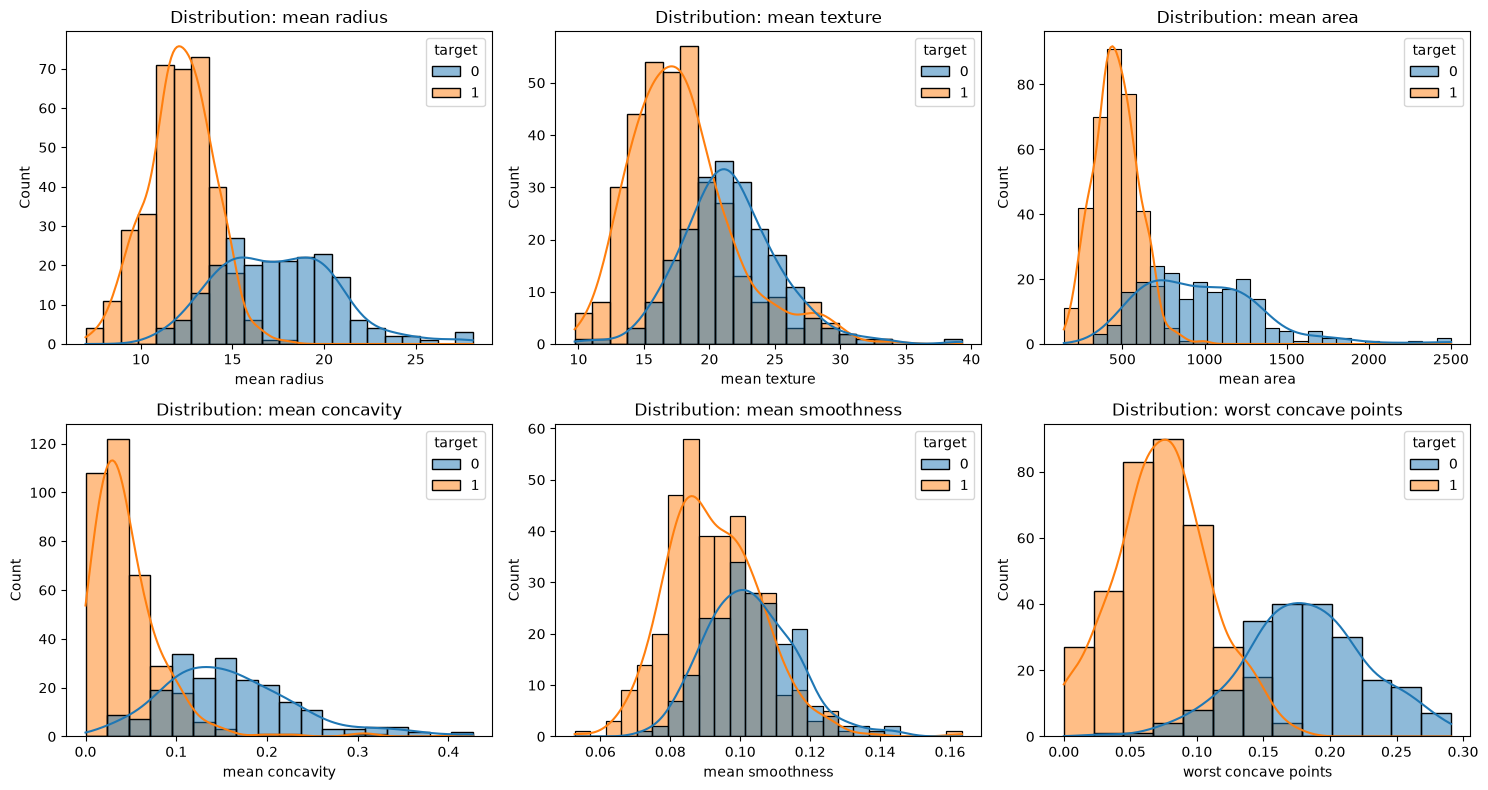

In [68]:
# Distribution plots for selected numerical features (per class)
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), selected_features):
    sns.histplot(data=df, x=col, hue="target", kde=True,ax=ax)
    ax.set_title(f"Distribution: {col}")
plt.tight_layout()
plt.show()

## EDA Summary

- **Class balance:** The classes are *moderately imbalanced*: 357 samples of class 1 (benign, ~63%) vs 212 of class 0 (malignant, ~37%). Not severe, but accuracy alone can mislead, so also track precision/recall/F1 and use a **stratified** train/test split.
- **Correlated features:** Yes, many features are highly correlated (multicollinearity). Size features (`radius`, `perimeter`, `area`) are almost perfectly correlated (> 0.95), and the `mean` and `worst` versions of the same measurement are strongly related. Compactness / concavity / concave points are also correlated. Some redundant features could be dropped (or PCA used), though an ANN can cope with it.
- **Outliers:** Yes, the boxplots show visible outliers, mostly on the high side, in features such as `mean area`, `mean radius`, `mean concavity` and the `error` features. The distributions are right-skewed and the outliers are most likely real large tumors, not errors, so we keep them but **must scale** the features (e.g. `StandardScaler` fitted on the training set only).
- **Useful features:** `worst concave points`, `worst perimeter`, `mean concave points`, `worst radius`, `mean perimeter`, `worst area`, `mean radius` and `mean concavity` have the strongest (negative) correlation with the target (about -0.7 to -0.8), and their distributions are clearly separated between the classes. `mean fractal dimension`, `texture error`, `symmetry error` and `smoothness error` have almost no correlation with the target and look less useful.

> Numbers are the well-known statistics of this dataset; confirm them against the outputs of the cells above after running.

In [72]:
#Step 4: Prepare the Features and Target
"""
Already seperated features and target, no categorical features, no missing values, no duplicates,and outliers are not too much (only a few features have outliers, and they are not extreme). So we can proceed to scaling and splitting the data.
"""
print(selected_features) # final selected features to use for modeling.
df_selected_features = df[selected_features]
print(df_selected_features.head())

['mean radius', 'mean texture', 'mean area', 'mean concavity', 'mean smoothness', 'worst concave points']
   mean radius  mean texture  ...  mean smoothness  worst concave points
0        17.99         10.38  ...          0.11840                0.2654
1        20.57         17.77  ...          0.08474                0.1860
2        19.69         21.25  ...          0.10960                0.2430
3        11.42         20.38  ...          0.14250                0.2575
4        20.29         14.34  ...          0.10030                0.1625

[5 rows x 6 columns]


In [73]:
# Step 5: Train-Test Split
from sklearn.model_selection import train_test_split

Xtrain, Xtest, ytrain, ytest = train_test_split(df_selected_features, target, test_size=0.2, random_state=42, stratify=target)

print(Xtrain.shape)
print(Xtest.shape)
print(ytrain.shape)
print(ytest.shape)

(455, 6)
(114, 6)
(455,)
(114,)


In [74]:
# Step 6: Scale the Data Without Data Leakage
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
Xtrain_scaled = scaler.fit_transform(Xtrain)
Xtest_scaled = scaler.transform(Xtest)

In [85]:
# Step 7: Build the Baseline ANN Model
model = tf.keras.Sequential()

# input layer --- flatten 30*1
model.add(tf.keras.layers.Input(shape=(Xtrain_scaled.shape[1],)))

# Hidden layers 3 + layers
model.add(tf.keras.layers.Dense(128,activation=tf.keras.activations.relu))
model.add(tf.keras.layers.Dense(64,activation=tf.keras.activations.relu))
model.add(tf.keras.layers.Dense(32,activation=tf.keras.activations.relu))

#output layer 1 neuron with sigmoid for binary classification (0 or 1)
model.add(tf.keras.layers.Dense(1,activation=tf.keras.activations.sigmoid)) # sigmoid for binary classification

In [86]:
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss=tf.keras.losses.BinaryCrossentropy(), metrics=["accuracy"])
# suitable loss function for binary classification is BinaryCrossentropy.

In [ ]:
# Step 8: Train the Baseline Model
model.fit(Xtrain_scaled, ytrain, epochs=10, batch_size=32, validation_split=0.2)

Epoch 1/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.8764 - loss: 0.5713 - val_accuracy: 0.9780 - val_loss: 0.4504
Epoch 2/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9505 - loss: 0.3520 - val_accuracy: 0.9670 - val_loss: 0.2484
Epoch 3/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9533 - loss: 0.2002 - val_accuracy: 0.9780 - val_loss: 0.1395
Epoch 4/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9478 - loss: 0.1408 - val_accuracy: 0.9670 - val_loss: 0.1069
Epoch 5/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9560 - loss: 0.1169 - val_accuracy: 0.9670 - val_loss: 0.0936
Epoch 6/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9533 - loss: 0.1084 - val_accuracy: 0.9670 - val_loss: 0.0865
Epoch 7/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9533 - loss: 0.1026 - val_accuracy: 0.9780 - val_loss: 0.0828
Epoch 8/10
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9588 - loss: 0.0968 - val_accuracy: 0.9780 - val_loss

Training accuracy: 0.9780  (loss: 0.0831)
Test accuracy:     0.9211  (loss: 0.1644)

Confusion Matrix:
 [[40  2]
 [ 7 65]]


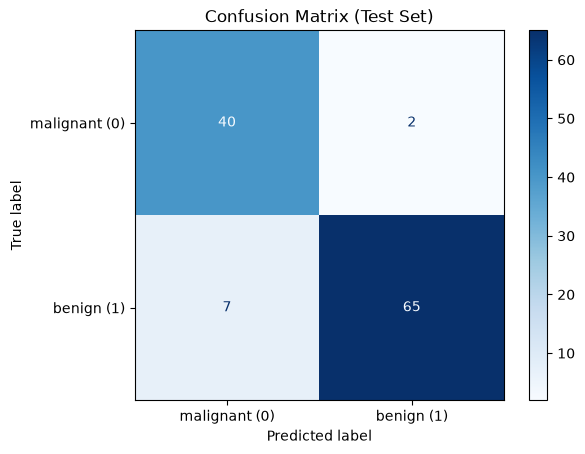


Precision: 0.9701
Recall:    0.9028
F1-score:  0.9353

Classification Report:

               precision    recall  f1-score   support

malignant (0)       0.85      0.95      0.90        42
   benign (1)       0.97      0.90      0.94        72

     accuracy                           0.92       114
    macro avg       0.91      0.93      0.92       114
 weighted avg       0.93      0.92      0.92       114



In [90]:
# Step 9: Evaluate the Baseline Model
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, precision_score,
                             recall_score, f1_score, classification_report)

# 1) Training and test accuracy
train_loss, train_acc = model.evaluate(Xtrain_scaled, ytrain, verbose=0)
test_loss, test_acc = model.evaluate(Xtest_scaled, ytest, verbose=0)
print(f"Training accuracy: {train_acc:.4f}  (loss: {train_loss:.4f})")
print(f"Test accuracy:     {test_acc:.4f}  (loss: {test_loss:.4f})")

# 2) Predictions: sigmoid probabilities -> class labels using a 0.5 threshold
y_pred_prob = model.predict(Xtest_scaled, verbose=0)
y_pred = (y_pred_prob > 0.5).astype(int).ravel()

# 3) Confusion matrix
cm = confusion_matrix(ytest, y_pred)
print("\nConfusion Matrix:\n", cm)
ConfusionMatrixDisplay(cm, display_labels=["malignant (0)", "benign (1)"]).plot(cmap="Blues")
plt.title("Confusion Matrix (Test Set)")
plt.show()

# 4) Precision, recall, F1 (for class 1 = benign)
print(f"\nPrecision: {precision_score(ytest, y_pred):.4f}")
print(f"Recall:    {recall_score(ytest, y_pred):.4f}")
print(f"F1-score:  {f1_score(ytest, y_pred):.4f}")

# 5) Classification report
print("\nClassification Report:\n")
print(classification_report(ytest, y_pred, target_names=["malignant (0)", "benign (1)"]))

In [ ]:
"""
The model has good accuracy, precision, recall, and F1-score. It doesn't seem to be overfitting or underfitting. The confusion matrix shows that the model is able to correctly classify most of the samples. The classification report provides a detailed breakdown of the model's performance for each class.
"""